# BAN4550 Project 3: bar chart, t-test, regression, and a peer industry

<div style="background:#e8f1fb; border-left:6px solid #2b6cb0; padding:8px 14px"><b>Goal.</b> Project 2 built one row per earnings announcement (one company and one fiscal quarter) with two numbers:
the <b>SUE</b> (the earnings surprise) and the <b>3-day CAR</b> (the stock reaction on days −1, 0 and +1).
Here we answer the Project 3 question with that table: <b>do bigger earnings surprises go with bigger stock reactions,
and is it the same in a peer industry?</b><br>
<b>Name:</b> Bea Macalalag &nbsp;|&nbsp; <b>Industry:</b> SIC 38, Medical Instruments &nbsp;|&nbsp; <b>Peer industry:</b> SIC 13, Oil and Gas Extraction &nbsp;|&nbsp; <b>Client:</b> Stryker (SYK)</div>

**Plan**

| Part | What | Used in Project 3 for |
|---|---|---|
| 1 | Build the table (Project 2 code: quarterly SUE, daily returns, 3-day CAR) | the SIC 38 announcement table |
| 2a, 2b | Three groups and a **better-looking bar chart**: SIC 38 (2a) and SIC 13 (2b) previews | the groups behind Figure 1 |
| 3 | **t-test**: is High different from Low? | one sentence for Harry |
| 4a, 4b | Outliers and **regression**, models (1) to (3): SIC 38 (4a) and SIC 13 (4b) | the main result |
| 5 | **A class** (OOP): the same steps for SIC 13 in one line | the peer comparison: Figures 1, 2 and 3, and the cumulative abnormal return chart |
| 6 | **Figures for slides**: Figures 1 to 3 and the day −5 to +5 chart, made presentation-ready | slides 4 to 6 |
| 7 | Checklist for the Project 3 report and slides | |

**How to read this notebook.** The class notebook was annual and monthly; this project is quarterly and daily. The analysis code is the same, with these names (from the class mapping table):

| Class Notebook| Project |
|---|---|
| `events` | `events` (one row = one earnings announcement) |
| `eps_chg` (EPS change) | `sue` |
| `abn_ret` (12-month abnormal return) | `car` (3-day CAR) |
| `group` (Low / Middle / High) | `sue_group` |

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Setup. Libraries and settings</h2>

In [1]:
# ===== Setup (class notebook; changed the settings to Project 2, added summary_col and the figures folder) =====
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import seaborn as sns                      # a library on top of matplotlib: nicer defaults with less code
from scipy import stats                    # t-test
import statsmodels.formula.api as smf      # regression with a full results table
from statsmodels.iolib.summary2 import summary_col   # models (1) to (3) side by side
import wrds

conn = wrds.Connection()

# Settings (the same as Project 2). Change them here only.
SIC        = "38"           # my industry (Medical Instruments)
PEER_SIC   = "13"           # the peer industry for Part 5 (Oil and Gas Extraction)
ANN_START  = "2021-01-01"   # we study announcements (rdq) between ANN_START and ANN_END
ANN_END    = "2024-12-31"
PULL_START = "2019-01-01"   # SUE needs the EPS of four quarters before
RET_START  = "2020-12-01"   # covers day -5 of a January 2021 announcement
RET_END    = "2025-01-31"   # covers day +5 of a December 2024 announcement
MIN_PRC    = 5              # rule: last quarter's price is at least this
MAX_SUE    = 1              # rule: |SUE| is at most this

LABELS = ["Low", "Middle", "High"]
os.makedirs("figures", exist_ok=True)      # Figures 1 to 3 are saved here for the slides and GitHub

Loading library list...
Done


If `import seaborn` or `import statsmodels` gives an error, run `!pip install seaborn statsmodels` in a new cell once, then restart the kernel.

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 1. Build the table (Project 2 code)</h2>

<div style="background:#e8f1fb; border-left:6px solid #2b6cb0; padding:8px 14px">
The result is <code>events</code>: one row = one earnings announcement (one company and one fiscal quarter), with <code>sue</code> and <code>car</code>.
Rules: (1) the announcement date is known, (2) it is between 2021 and 2024, (3) SUE can be computed, (4) last quarter's price is at least $5, (5) |SUE| ≤ 1, (6) all 3 daily abnormal returns are found.</div>

In [2]:
# ===== Steps 1-2. Link file and Compustat quarterly data (Project 2 code) =====
link_all = pd.read_csv("ccm_link.csv", dtype=str)
link_all["gvkey"]     = link_all["gvkey"].str.zfill(6)
link_all["permno"]    = pd.to_numeric(link_all["permno"]).astype(int)
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

link = link_all[link_all["sic2"] == SIC].reset_index(drop=True)

gv = "'" + "','".join(link["gvkey"].unique()) + "'"
fq = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
    from comp.fundq
    where gvkey in ({gv})
      and datadate between '{PULL_START}' and '{ANN_END}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
""", date_cols=["datadate", "rdq"])
fq["epspxq"] = fq["epspxq"].astype("float64")
fq["prccq"]  = fq["prccq"].astype("float64")
fq = fq.dropna(subset=["fyearq", "fqtr"])
print("company-quarters pulled:", len(fq))

company-quarters pulled: 3865


In [3]:
# ===== Step 3. Merge 1 (link), Merge 2 (earlier quarters), SUE, Rules 1-5 (Project 2 code) =====
panel = fq.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
panel = panel[(panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])]
panel = panel.drop_duplicates(["gvkey", "fyearq", "fqtr"]).drop(columns=["linkdt", "linkenddt"])

panel["qnum"] = panel["fyearq"] * 4 + panel["fqtr"]          # quarter number: 2022 Q1 = 2022 * 4 + 1
lag4 = panel[["gvkey", "qnum", "epspxq"]].copy()
lag4["qnum"] = lag4["qnum"] + 4                              # EPS of four quarters before
lag4 = lag4.rename(columns={"epspxq": "eps_lag4"})
lag1 = panel[["gvkey", "qnum", "prccq"]].copy()
lag1["qnum"] = lag1["qnum"] + 1                              # price of last quarter
lag1 = lag1.rename(columns={"prccq": "prc_lag1"})
panel = panel.merge(lag4, on=["gvkey", "qnum"], how="left")
panel = panel.merge(lag1, on=["gvkey", "qnum"], how="left")
panel["sue"] = (panel["epspxq"] - panel["eps_lag4"]) / panel["prc_lag1"]

events = panel[panel["rdq"].notna()]                                          # Rule 1
events = events[(events["rdq"] >= ANN_START) & (events["rdq"] <= ANN_END)]    # Rule 2
events = events[events["sue"].notna()]                                        # Rule 3
events = events[events["prc_lag1"] >= MIN_PRC]                                # Rule 4
events = events[events["sue"].abs() <= MAX_SUE].reset_index(drop=True)        # Rule 5
print("announcements after Rules 1 to 5:", len(events))

announcements after Rules 1 to 5: 1775


In [4]:
# ===== Steps 4-6. Daily returns, day 0, 3-day CAR, Rule 6 (Project 2 code) =====
permnos = ",".join(events["permno"].astype(str).unique())
stock = conn.raw_sql(f"""select permno, date, ret from crsp.dsf
                         where permno in ({permnos}) and date between '{RET_START}' and '{RET_END}'""",
                     date_cols=["date"])
mkt = conn.raw_sql(f"""select date, vwretd from crsp.dsi
                       where date between '{RET_START}' and '{RET_END}'""", date_cols=["date"])
stock["permno"] = stock["permno"].astype(int)
stock["ret"]    = stock["ret"].astype("float64")
mkt["vwretd"]   = mkt["vwretd"].astype("float64")
mkt = mkt.sort_values("date").reset_index(drop=True)
mkt["tday"] = mkt.index + 1                                  # trading-day number 1, 2, 3, ...
stock = stock.merge(mkt[["date", "vwretd", "tday"]], on="date", how="left")    # Merge 3
stock["ar"] = stock["ret"] - stock["vwretd"]

events = events.sort_values("rdq").reset_index(drop=True)
events["event_id"] = events.index
calendar = mkt[["date", "tday"]].rename(columns={"date": "day0", "tday": "n"})
events = pd.merge_asof(events, calendar, left_on="rdq", right_on="day0", direction="forward")   # Merge 4: day 0
pairs = events[["event_id", "permno", "n"]].merge(stock[["permno", "tday", "ar"]], on="permno", how="inner")   # Merge 5
pairs = pairs[(pairs["tday"] >= pairs["n"] - 1) & (pairs["tday"] <= pairs["n"] + 1)]    # days -1, 0, +1
abn = pairs.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
abn = abn.rename(columns={"sum": "car", "count": "days_found"})
events = events.merge(abn, on="event_id", how="left")
events = events[events["days_found"] == 3].reset_index(drop=True)              # Rule 6

print("final table:", len(events), "announcements |", events["gvkey"].nunique(), "companies")
events[["sue", "car"]].describe()

final table: 1768 announcements | 151 companies


,sue,car
count,1768.000000,1768.000000
mean,0.000153,-0.001883
std,0.045162,0.100863
min,-0.678407,-0.638571
25%,-0.003572,-0.051706
50%,0.000615,-0.004225
75%,0.004298,0.049295
max,0.841346,0.522563


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 2a. SIC 38 three groups (Medical Instruments)</h2>

**Step 1. Three equal groups.** We rank `sue` first, so that equal values are split evenly and the three groups have the same size.

For each group we compute the average and its **95% confidence interval** (CI):

- standard error = standard deviation ÷ √(number of rows)
- 95% CI = average ± 1.96 × standard error

The CI shows how much the average could move just by luck. A short bar with a long CI tells us little.

In [5]:
# ===== 2a. Groups and the table behind Figure 1 =====
events["sue_group"] = pd.qcut(events["sue"].rank(method="first"), 3, labels=LABELS)

table = events.groupby("sue_group", observed=True)["car"].agg(n="count", mean="mean", sd="std")
table["se"]   = table["sd"] / np.sqrt(table["n"])
table["ci95"] = 1.96 * table["se"]

print("SIC 38 · Medical Instruments: average 3-day CAR and 95% CI by SUE group (in %)")
(table[["mean", "ci95"]] * 100).round(2).assign(n=table["n"])     # in %, easier to read

SIC 38 · Medical Instruments: average 3-day CAR and 95% CI by SUE group (in %)


,mean,ci95,n
sue_group,,,
Low,-2.01,0.82,589
Middle,-0.28,0.69,589
High,1.72,0.89,590


**Step 2. The quick chart.** This is what one line of pandas gives us. It is fine for checking, but not for a client:
no title that says anything, no units, no uncertainty, the labels are rotated, and the colors mean nothing.

<Axes: title={'center': 'SIC 38 · Medical Instruments'}, xlabel='sue_group'>

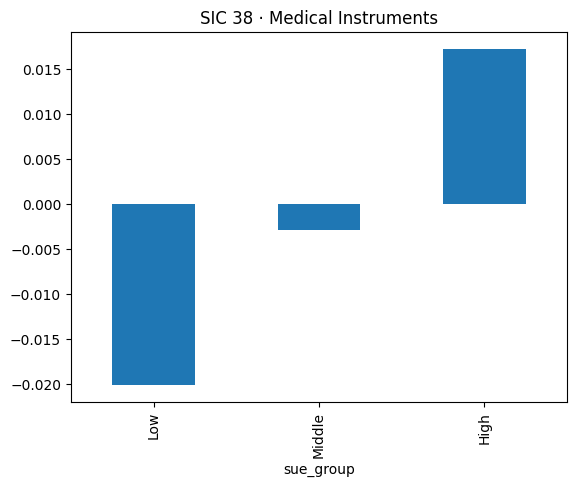

In [6]:
# ===== 2b. The quick (default) chart =====
table["mean"].plot(kind="bar", title="SIC 38 · Medical Instruments")

**Step 3. The same chart, made for a client.** Six small changes do most of the work:

1. a **theme** (`sns.set_theme`) for a clean background and readable fonts
2. **colors with a meaning**: red = low surprise, grey = middle, blue = high (use the same colors on every slide)
3. **error bars** = the 95% CI
4. the **value and n** written on each bar, so nobody has to read the axis
5. a **title that states the finding** (built from the numbers, so it is always right)
6. no box around the plot (`sns.despine`), and a line at 0

We save the figure as a PNG for the slides.

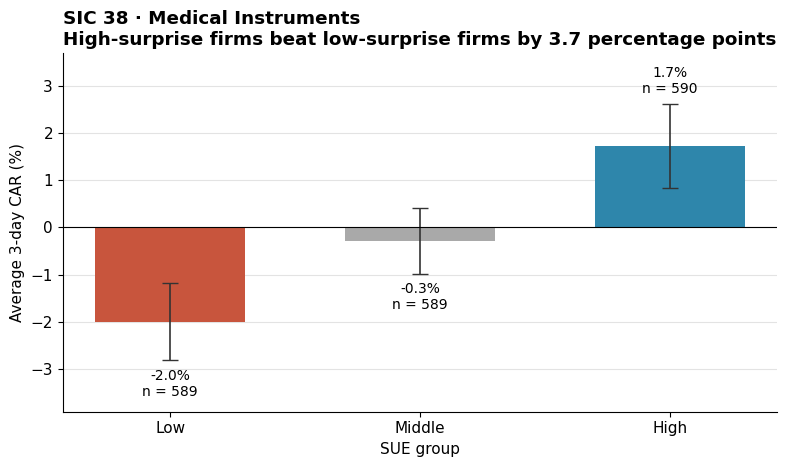

In [7]:
# ===== 2c. SIC 38 preview of the bar chart, made for a client (the official Figure 1 with both industries is in Part 5) =====

plt.rcParams.update({
    "font.size": 11, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#E3E3E3",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
#sns.set_theme(style="whitegrid", font_scale=1.1, rc={"axes.grid.axis": "y"})   # 1. theme (once per notebook), horizontal lines only

COLORS = {"Low": "#C8553D", "Middle": "#A9A9A9", "High": "#2E86AB"}    # 2. colors with a meaning

mean = table["mean"] * 100
ci   = table["ci95"] * 100
spread = mean["High"] - mean["Low"]
word = "beat" if spread > 0 else "trail"
title = (f"SIC 38 · Medical Instruments\n"                                                       # which industry
         f"High-surprise firms {word} low-surprise firms by {abs(spread):.1f} percentage points")   # 5. the finding

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(LABELS, mean, yerr=ci, capsize=6, width=0.6,                  # 3. error bars = 95% CI
       color=[COLORS[g] for g in LABELS], error_kw={"elinewidth": 1.2, "ecolor": "#333333"})
for i, g in enumerate(LABELS):                                        # 4. value and n on each bar
    top = mean[g] + ci[g] if mean[g] >= 0 else mean[g] - ci[g]
    ax.annotate(f"{mean[g]:.1f}%\nn = {table.loc[g, 'n']}", (i, top),
                xytext=(0, 6 if mean[g] >= 0 else -6), textcoords="offset points",
                ha="center", va="bottom" if mean[g] >= 0 else "top", fontsize=10)
ax.axhline(0, color="black", linewidth=0.8)                           # 6. line at 0
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("SUE group")
ax.set_ylabel("Average 3-day CAR (%)")
ax.margins(y=0.2)
#sns.despine(left=True)                                                # 6. no box
plt.tight_layout()
fig.savefig("preview_sic38_groups.png", dpi=200)                       # preview only; Figure 1 is in Part 5
plt.show()

<div style="background:#eaf7ee; border-left:6px solid #2f855a; padding:8px 14px"><b>Read the chart before you test.</b> Do the error bars of Low and High overlap?
If they do not overlap, the difference is very unlikely to be luck. If they overlap a lot, the t-test will probably say "could be luck".</div>

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 2b. SIC 13 three groups (Oil &amp; Gas Extraction)</h2>

<div style="background:#e8f1fb; border-left:6px solid #2b6cb0; padding:8px 14px">The same descriptive statistics and charts as Part 2a, for the peer industry, to see the comparison before the tests.
First, one cell builds the SIC 13 table with exactly the Part 1 steps and Rules 1 to 6 (the same code, with <code>PEER_SIC</code> in place of <code>SIC</code>).
The result is <code>events13</code>; the SIC 38 table <code>events</code> is not changed. Part 5 builds SIC 13 again inside the <code>Industry</code> class, with the same steps, so the numbers match.</div>

In [8]:
# ===== SIC 13 · Build the table: Part 1 steps for the peer industry (copy of Part 1; AI, see README) =====
link13 = link_all[link_all["sic2"] == PEER_SIC].reset_index(drop=True)
gv13 = "'" + "','".join(link13["gvkey"].unique()) + "'"
fq13 = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
    from comp.fundq
    where gvkey in ({gv13})
      and datadate between '{PULL_START}' and '{ANN_END}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
""", date_cols=["datadate", "rdq"])
fq13[["epspxq", "prccq"]] = fq13[["epspxq", "prccq"]].astype("float64")
fq13 = fq13.dropna(subset=["fyearq", "fqtr"])

panel13 = fq13.merge(link13[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")   # Merge 1
panel13 = panel13[(panel13["linkdt"] <= panel13["datadate"]) & (panel13["datadate"] <= panel13["linkenddt"])]
panel13 = panel13.drop_duplicates(["gvkey", "fyearq", "fqtr"]).drop(columns=["linkdt", "linkenddt"])
panel13["qnum"] = panel13["fyearq"] * 4 + panel13["fqtr"]
lag4 = panel13[["gvkey", "qnum", "epspxq"]].copy()
lag4["qnum"] = lag4["qnum"] + 4
lag4 = lag4.rename(columns={"epspxq": "eps_lag4"})
lag1 = panel13[["gvkey", "qnum", "prccq"]].copy()
lag1["qnum"] = lag1["qnum"] + 1
lag1 = lag1.rename(columns={"prccq": "prc_lag1"})
panel13 = panel13.merge(lag4, on=["gvkey", "qnum"], how="left")                                            # Merge 2
panel13 = panel13.merge(lag1, on=["gvkey", "qnum"], how="left")
panel13["sue"] = (panel13["epspxq"] - panel13["eps_lag4"]) / panel13["prc_lag1"]

events13 = panel13[panel13["rdq"].notna()]                                            # Rule 1
events13 = events13[(events13["rdq"] >= ANN_START) & (events13["rdq"] <= ANN_END)]    # Rule 2
events13 = events13[events13["sue"].notna()]                                          # Rule 3
events13 = events13[events13["prc_lag1"] >= MIN_PRC]                                  # Rule 4
events13 = events13[events13["sue"].abs() <= MAX_SUE].reset_index(drop=True)          # Rule 5
print("SIC 13 · Oil & Gas Extraction: announcements after Rules 1 to 5:", len(events13))

permnos13 = ",".join(events13["permno"].astype(str).unique())
stock13 = conn.raw_sql(f"""select permno, date, ret from crsp.dsf
                           where permno in ({permnos13}) and date between '{RET_START}' and '{RET_END}'""",
                       date_cols=["date"])
stock13["permno"] = stock13["permno"].astype(int)
stock13["ret"]    = stock13["ret"].astype("float64")
stock13 = stock13.merge(mkt[["date", "vwretd", "tday"]], on="date", how="left")      # Merge 3 (mkt from Part 1)
stock13["ar"] = stock13["ret"] - stock13["vwretd"]

events13 = events13.sort_values("rdq").reset_index(drop=True)
events13["event_id"] = events13.index
calendar = mkt[["date", "tday"]].rename(columns={"date": "day0", "tday": "n"})
events13 = pd.merge_asof(events13, calendar, left_on="rdq", right_on="day0", direction="forward")   # Merge 4: day 0
pairs13 = events13[["event_id", "permno", "n"]].merge(stock13[["permno", "tday", "ar"]], on="permno", how="inner")   # Merge 5
pairs13 = pairs13[(pairs13["tday"] >= pairs13["n"] - 1) & (pairs13["tday"] <= pairs13["n"] + 1)]
abn13 = pairs13.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
abn13 = abn13.rename(columns={"sum": "car", "count": "days_found"})
events13 = events13.merge(abn13, on="event_id", how="left")
events13 = events13[events13["days_found"] == 3].reset_index(drop=True)              # Rule 6

print("SIC 13 · Oil & Gas Extraction: final table:", len(events13), "announcements |", events13["gvkey"].nunique(), "companies")
events13[["sue", "car"]].describe()

SIC 13 · Oil & Gas Extraction: announcements after Rules 1 to 5: 1506
SIC 13 · Oil & Gas Extraction: final table: 1497 announcements | 130 companies


,sue,car
count,1497.000000,1497.000000
mean,0.019799,0.006067
std,0.133979,0.069109
min,-0.907073,-0.252057
25%,-0.014467,-0.031995
50%,0.005411,0.003780
75%,0.039752,0.041430
max,0.942852,0.426323


**SIC 13 · Step 1. Three equal groups.** The same as Part 2a: rank `sue`, cut into three equal groups, and compute each group's average CAR with its 95% confidence interval.

In [9]:
# ===== SIC 13 · 2a. Groups and the table (copy of 2a) =====
events13["sue_group"] = pd.qcut(events13["sue"].rank(method="first"), 3, labels=LABELS)

table13 = events13.groupby("sue_group", observed=True)["car"].agg(n="count", mean="mean", sd="std")
table13["se"]   = table13["sd"] / np.sqrt(table13["n"])
table13["ci95"] = 1.96 * table13["se"]

print("SIC 13 · Oil & Gas Extraction: average 3-day CAR and 95% CI by SUE group (in %)")
(table13[["mean", "ci95"]] * 100).round(2).assign(n=table13["n"])     # in %, easier to read

SIC 13 · Oil & Gas Extraction: average 3-day CAR and 95% CI by SUE group (in %)


,mean,ci95,n
sue_group,,,
Low,-0.45,0.59,499
Middle,1.24,0.59,499
High,1.04,0.63,499


**SIC 13 · Step 2. The quick chart.** The same one-line default chart as Part 2a, for checking.

<Axes: title={'center': 'SIC 13 · Oil & Gas Extraction'}, xlabel='sue_group'>

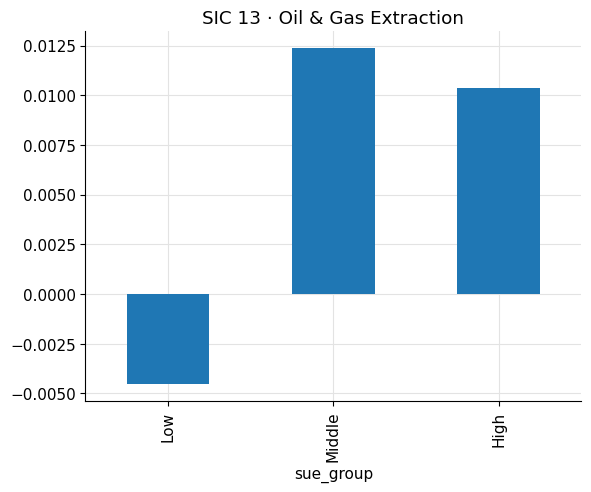

In [10]:
# ===== SIC 13 · 2b. The quick (default) chart (copy of 2b) =====
table13["mean"].plot(kind="bar", title="SIC 13 · Oil & Gas Extraction")

**SIC 13 · Step 3. The same chart, made for a client.** The same six changes and the same group colors as Part 2a (red = low surprise, grey = middle, blue = high), so the two previews can be compared directly.

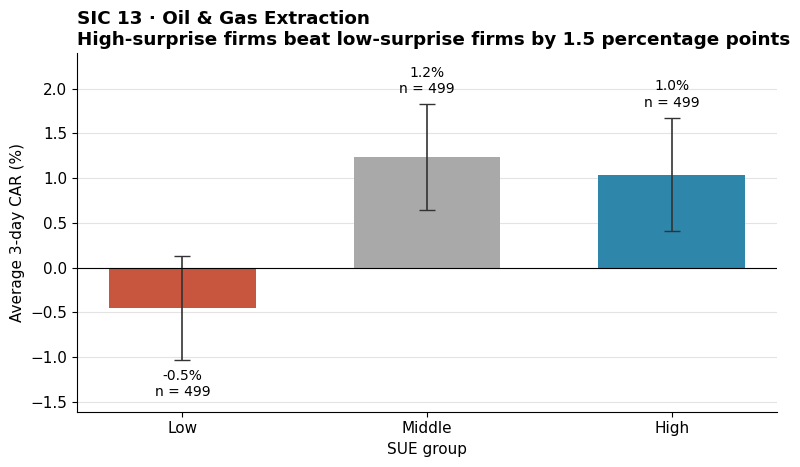

In [11]:
# ===== SIC 13 · 2c. Preview of the bar chart, made for a client (copy of 2c; the official Figure 1 with both industries is in Part 5) =====
mean13 = table13["mean"] * 100
ci13   = table13["ci95"] * 100
spread13 = mean13["High"] - mean13["Low"]
word13 = "beat" if spread13 > 0 else "trail"
title13 = (f"SIC 13 · Oil & Gas Extraction\n"
           f"High-surprise firms {word13} low-surprise firms by {abs(spread13):.1f} percentage points")

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(LABELS, mean13, yerr=ci13, capsize=6, width=0.6,
       color=[COLORS[g] for g in LABELS], error_kw={"elinewidth": 1.2, "ecolor": "#333333"})
for i, g in enumerate(LABELS):                                        # value and n on each bar
    top = mean13[g] + ci13[g] if mean13[g] >= 0 else mean13[g] - ci13[g]
    ax.annotate(f"{mean13[g]:.1f}%\nn = {table13.loc[g, 'n']}", (i, top),
                xytext=(0, 6 if mean13[g] >= 0 else -6), textcoords="offset points",
                ha="center", va="bottom" if mean13[g] >= 0 else "top", fontsize=10)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(title13, loc="left", fontweight="bold")
ax.set_xlabel("SUE group")
ax.set_ylabel("Average 3-day CAR (%)")
ax.margins(y=0.2)
plt.tight_layout()
fig.savefig("preview_sic13_groups.png", dpi=200)                       # preview only; Figure 1 is in Part 5
plt.show()

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 3. t-test: is High different from Low?</h2>

The **null hypothesis**: High and Low have the same average, and the gap we see is luck.

- **t-statistic** = the gap ÷ its standard error. Beyond about ±2, the gap is large compared with the noise.
- **p-value** = if there were really no difference, how often would we see a gap this large just by luck?
  Below 0.05 we say "unlikely to be luck".

We use Welch's t-test (`equal_var=False`): it does not assume the two groups have the same spread.

In [12]:
# ===== 3. Welch t-test: High vs Low =====
high = events.loc[events["sue_group"] == "High", "car"]
low  = events.loc[events["sue_group"] == "Low",  "car"]

t, p = stats.ttest_ind(high, low, equal_var=False)

gap = (high.mean() - low.mean()) * 100
print(f"High - Low = {gap:.2f} percentage points | t = {t:.2f} | p = {p:.4f}")

High - Low = 3.73 percentage points | t = 6.04 | p = 0.0000


**Say it to Harry in two sentences** (fill in your numbers):

> *High-surprise firms earned on average X percentage points more than low-surprise firms.
> If there were really no difference, a gap this large would appear by luck about p × 100% of the time, so we treat it as real (p < 0.05) / we cannot rule out luck (p ≥ 0.05).*

A large p-value does **not** prove there is no difference. It means our data cannot tell.

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 4a. SIC 38 Outliers and the regression (Medical Instruments)</h2>

The t-test uses only High and Low. A **regression** uses **every row** and asks: when SUE goes up, how much does the 3-day CAR go up on average?

$$\text{car} = a + b \times \text{sue}$$

**Step 1. Outliers.** A few extreme values can pull the line. Rules 4 and 5 already removed the worst SUEs.
For the return, a common fix is to **winsorize**: values below the 1st percentile are set to the 1st percentile, values above the 99th to the 99th.
No row is deleted, only the most extreme values are pulled in. We run the regression both ways and compare.

In [13]:
# ===== 4a. Look at the extremes, then winsorize the return at 1% and 99% =====
print("SIC 38 · Medical Instruments: SUE and 3-day CAR before winsorizing")
print(events[["sue", "car"]].describe().round(3))

lo, hi = events["car"].quantile([0.01, 0.99])
events["car_w"] = events["car"].clip(lo, hi)     # clip = pull values outside [lo, hi] to the edge
print(f"\nSIC 38 · rows changed by winsorizing: {(events['car'] != events['car_w']).sum()} of {len(events)}")

SIC 38 · Medical Instruments: SUE and 3-day CAR before winsorizing
            sue       car
count  1768.000  1768.000
mean      0.000    -0.002
std       0.045     0.101
min      -0.678    -0.639
25%      -0.004    -0.052
50%       0.001    -0.004
75%       0.004     0.049
max       0.841     0.523

SIC 38 · rows changed by winsorizing: 36 of 1768


**Step 2. The regression.** `smf.ols("y ~ x", data=...)` reads like the formula. The table below has everything we need:

| Number | Where | What it means |
|---|---|---|
| **b** (slope) | `coef` of `sue` | the change in `car` when `sue` goes up by 1 |
| **p-value of b** | `P>|t|` of `sue` | could the true slope be 0? |
| **R²** | `R-squared` | the share of the ups and downs in `car` that `sue` explains (0 to 1) |

In [14]:
# ===== 4b. Regression: original and winsorized =====
model   = smf.ols("car ~ sue", data=events).fit()
model_w = smf.ols("car_w ~ sue", data=events).fit()

print("SIC 38 · Medical Instruments: base regression, original CAR")
print(model.summary())      # full results table, original
print("\nSIC 38 · Medical Instruments: base regression, winsorized CAR")
print(model_w.summary())    # full results table, winsorized

results = pd.DataFrame({
    "b (slope)":    [model.params["sue"],  model_w.params["sue"]],
    "p-value of b": [model.pvalues["sue"], model_w.pvalues["sue"]],
    "R-squared":    [model.rsquared,           model_w.rsquared],
    "n":            [int(model.nobs),          int(model_w.nobs)],
}, index=["SIC 38 · original", "SIC 38 · winsorized 1%/99%"]).round(4)
results

SIC 38 · Medical Instruments: base regression, original CAR
                            OLS Regression Results                            
Dep. Variable:                    car   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     2.878
Date:                Mon, 23 Nov 2026   Prob (F-statistic):             0.0900
Time:                        12:52:22   Log-Likelihood:                 1549.0
No. Observations:                1768   AIC:                            -3094.
Df Residuals:                    1766   BIC:                            -3083.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

,b (slope),p-value of b,R-squared,n
SIC 38 · original,0.0901,0.0900,0.0016,1768
SIC 38 · winsorized 1%/99%,0.0848,0.0885,0.0016,1768


In [15]:
# ===== Models (1) to (3): base, year fixed effects, and loss interaction (class notebook; changed to fyearq and epspxq) =====
events["fyearq"] = events["fyearq"].astype(int)         # nullable Int64 -> plain int
events["loss"]   = (events["epspxq"] < 0).astype(int)   # 1 = loss announcement
lo, hi = events["car"].quantile([0.01, 0.99])
events["car_w"] = events["car"].clip(lo, hi)

cl = dict(cov_type="cluster", cov_kwds={"groups": events["gvkey"]})

m1 = smf.ols("car_w ~ sue", data=events).fit(**cl)
m2 = smf.ols("car_w ~ sue + C(fyearq)", data=events).fit(**cl)
m3 = smf.ols("car_w ~ sue * loss + C(fyearq)", data=events).fit(**cl)

summary_col([m1, m2, m3], stars=True,
            model_names=["(1) SIC 38 base", "(2) SIC 38 year FE", "(3) SIC 38 year FE + loss"],
            regressor_order=["sue", "loss", "sue:loss"], drop_omitted=True,
            info_dict={"R2": lambda m: f"{m.rsquared:.3f}", "n": lambda m: f"{int(m.nobs)}"})

,(1) SIC 38 base,(2) SIC 38 year FE,(3) SIC 38 year FE + loss
sue,0.0848,0.0830,0.1099
,(0.0609),(0.0620),(0.1138)
loss,,,-0.0167***
,,,(0.0061)
sue:loss,,,-0.1039
,,,(0.1305)
R-squared,0.0016,0.0040,0.0104
R-squared Adj.,0.0011,0.0006,0.0059
R2,0.002,0.004,0.010
n,1768,1768,1768


**Read b in plain words.** A SUE of 1 means EPS moved by 100% of the share price, which never happens. A change of **0.01** (1% of the price) is more natural:

> *When SUE is 0.01 higher, the 3-day CAR is on average b × 0.01 × 100 percentage points higher.*

**R² is small? That is normal.** Returns move for many reasons besides earnings. The surprise can matter on average (a clear slope)
and still explain little of any single company's return. This is a good **limitation** for your report.

If the original and the winsorized results tell the same story, say so: your result does not depend on a few extreme rows.

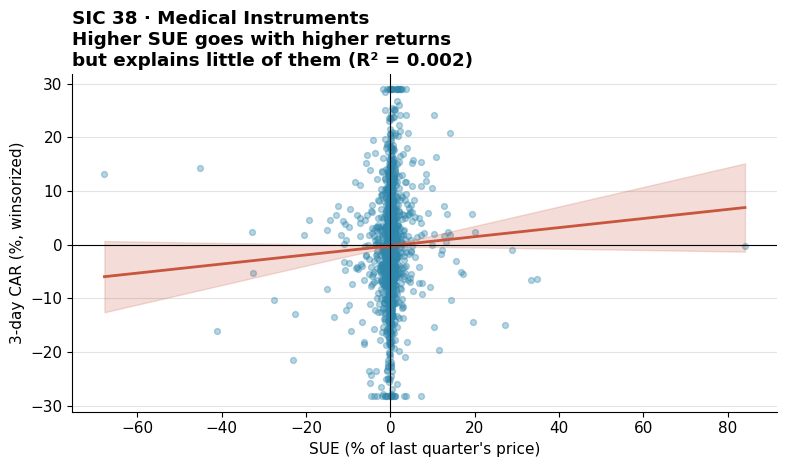

In [16]:
# ===== 4c. SIC 38 preview of the scatter: every announcement and the regression line (the official Figure 2 is in Part 5) =====
b  = model_w.params["sue"]
r2 = model_w.rsquared
title = (f"SIC 38 · Medical Instruments\n"
         f"Higher SUE goes with {'higher' if b > 0 else 'lower'} returns\n"
         f"but explains little of them (R² = {r2:.3f})")

# the regression line and its 95% band, from the fitted model
grid = pd.DataFrame({"sue": np.linspace(events["sue"].min(), events["sue"].max(), 100)})
pred = model_w.get_prediction(grid).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(events["sue"] * 100, events["car_w"] * 100,
           s=18, alpha=0.35, color="#2E86AB")                                   # every announcement
ax.fill_between(grid["sue"] * 100, pred["mean_ci_lower"] * 100, pred["mean_ci_upper"] * 100,
                color="#C8553D", alpha=0.2)                                     # 95% band
ax.plot(grid["sue"] * 100, pred["mean"] * 100, color="#C8553D", linewidth=2)  # regression line
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("SUE (% of last quarter's price)")
ax.set_ylabel("3-day CAR (%, winsorized)")
ax.spines[["top", "right"]].set_visible(False)                                  # no box
plt.tight_layout()
fig.savefig("preview_sic38_regression.png", dpi=200)     # preview only; Figure 2 is in Part 5
plt.show()

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 4b. SIC 13 Outliers and the regression (Oil &amp; Gas Extraction)</h2>

<div style="background:#e8f1fb; border-left:6px solid #2b6cb0; padding:8px 14px">The same steps as Part 4a, for the peer industry, using the SIC 13 table <code>events13</code> built in Part 2b:
winsorize CAR at 1% and 99%, run the base regression with the original and the winsorized CAR, then models (1) to (3) with standard errors clustered by company, and the preview scatter.
Part 5 runs the same models again inside the <code>Industry</code> class, so the numbers match.</div>

In [17]:
# ===== SIC 13 · 4a. Look at the extremes, then winsorize the return at 1% and 99% (copy of 4a) =====
print("SIC 13 · Oil & Gas Extraction: SUE and 3-day CAR before winsorizing")
print(events13[["sue", "car"]].describe().round(3))

lo13, hi13 = events13["car"].quantile([0.01, 0.99])
events13["car_w"] = events13["car"].clip(lo13, hi13)     # clip = pull values outside [lo, hi] to the edge
print(f"\nSIC 13 · rows changed by winsorizing: {(events13['car'] != events13['car_w']).sum()} of {len(events13)}")

SIC 13 · Oil & Gas Extraction: SUE and 3-day CAR before winsorizing
            sue       car
count  1497.000  1497.000
mean      0.020     0.006
std       0.134     0.069
min      -0.907    -0.252
25%      -0.014    -0.032
50%       0.005     0.004
75%       0.040     0.041
max       0.943     0.426

SIC 13 · rows changed by winsorizing: 30 of 1497


**SIC 13 · The regression.** The same base regression as Part 4a, `car ~ sue`, with the original and the winsorized CAR.

In [18]:
# ===== SIC 13 · 4b. Regression: original and winsorized (copy of 4b) =====
model13   = smf.ols("car ~ sue", data=events13).fit()
model13_w = smf.ols("car_w ~ sue", data=events13).fit()

print("SIC 13 · Oil & Gas Extraction: base regression, original CAR")
print(model13.summary())      # full results table, original
print("\nSIC 13 · Oil & Gas Extraction: base regression, winsorized CAR")
print(model13_w.summary())    # full results table, winsorized

results13 = pd.DataFrame({
    "b (slope)":    [model13.params["sue"],  model13_w.params["sue"]],
    "p-value of b": [model13.pvalues["sue"], model13_w.pvalues["sue"]],
    "R-squared":    [model13.rsquared,       model13_w.rsquared],
    "n":            [int(model13.nobs),      int(model13_w.nobs)],
}, index=["SIC 13 · original", "SIC 13 · winsorized 1%/99%"]).round(4)
results13

SIC 13 · Oil & Gas Extraction: base regression, original CAR
                            OLS Regression Results                            
Dep. Variable:                    car   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.006
Method:                 Least Squares   F-statistic:                     9.940
Date:                Mon, 23 Nov 2026   Prob (F-statistic):            0.00165
Time:                        12:52:22   Log-Likelihood:                 1881.4
No. Observations:                1497   AIC:                            -3759.
Df Residuals:                    1495   BIC:                            -3748.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------

,b (slope),p-value of b,R-squared,n
SIC 13 · original,0.0419,0.0016,0.0066,1497
SIC 13 · winsorized 1%/99%,0.0429,0.0007,0.0076,1497


In [19]:
# ===== SIC 13 · Models (1) to (3): base, year fixed effects, and loss interaction (copy of the Part 4a models) =====
events13["fyearq"] = events13["fyearq"].astype(int)          # nullable Int64 -> plain int
events13["loss"]   = (events13["epspxq"] < 0).astype(int)    # 1 = loss announcement

cl13 = dict(cov_type="cluster", cov_kwds={"groups": events13["gvkey"]})

m1_13 = smf.ols("car_w ~ sue", data=events13).fit(**cl13)
m2_13 = smf.ols("car_w ~ sue + C(fyearq)", data=events13).fit(**cl13)
m3_13 = smf.ols("car_w ~ sue * loss + C(fyearq)", data=events13).fit(**cl13)

summary_col([m1_13, m2_13, m3_13], stars=True,
            model_names=["(1) SIC 13 base", "(2) SIC 13 year FE", "(3) SIC 13 year FE + loss"],
            regressor_order=["sue", "loss", "sue:loss"], drop_omitted=True,
            info_dict={"R2": lambda m: f"{m.rsquared:.3f}", "n": lambda m: f"{int(m.nobs)}"})

,(1) SIC 13 base,(2) SIC 13 year FE,(3) SIC 13 year FE + loss
sue,0.0429***,0.0439***,0.0332**
,(0.0159),(0.0159),(0.0145)
loss,,,-0.0112**
,,,(0.0046)
sue:loss,,,0.0057
,,,(0.0232)
R-squared,0.0076,0.0217,0.0259
R-squared Adj.,0.0070,0.0177,0.0207
R2,0.008,0.022,0.026
n,1497,1497,1497


**SIC 13 · Read b in plain words.** The same reading as Part 4a: *when SUE is 0.01 higher, the 3-day CAR is on average b × 0.01 × 100 percentage points higher.*
Compare b, its p-value and R² with Part 4a: a steeper b means oil and gas stocks react more to each unit of surprise.

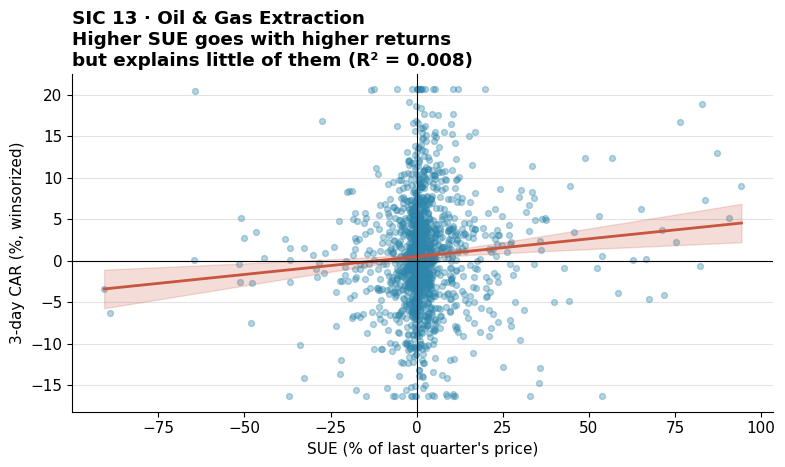

In [20]:
# ===== SIC 13 · 4c. Preview of the scatter: every announcement and the regression line (copy of 4c; the official Figure 2 is in Part 5) =====
b13  = model13_w.params["sue"]
r2_13 = model13_w.rsquared
title13 = (f"SIC 13 · Oil & Gas Extraction\n"
           f"Higher SUE goes with {'higher' if b13 > 0 else 'lower'} returns\n"
           f"but explains little of them (R² = {r2_13:.3f})")

grid13 = pd.DataFrame({"sue": np.linspace(events13["sue"].min(), events13["sue"].max(), 100)})
pred13 = model13_w.get_prediction(grid13).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(events13["sue"] * 100, events13["car_w"] * 100,
           s=18, alpha=0.35, color="#2E86AB")                                     # every announcement
ax.fill_between(grid13["sue"] * 100, pred13["mean_ci_lower"] * 100, pred13["mean_ci_upper"] * 100,
                color="#C8553D", alpha=0.2)                                       # 95% band
ax.plot(grid13["sue"] * 100, pred13["mean"] * 100, color="#C8553D", linewidth=2)  # regression line
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(title13, loc="left", fontweight="bold")
ax.set_xlabel("SUE (% of last quarter's price)")
ax.set_ylabel("3-day CAR (%, winsorized)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig("preview_sic13_regression.png", dpi=200)     # preview only; Figure 2 is in Part 5
plt.show()

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 5. The peer industry, with a class (OOP)</h2>

Project 3 asks for a **peer comparison**. We need Parts 1 to 4 again for another industry.

**Option 1: copy every cell and change `SIC`.** It works, but you now have two copies of everything.
Fix a bug in one copy and forget the other, and your two industries are no longer built the same way.

**Option 2: write the steps once, as a class, and use it twice.**

| Word | Meaning | Here |
|---|---|---|
| **class** | a recipe | `Industry`: how to build and analyze one industry |
| **object** | one thing made from the recipe | `mine = Industry("38", ...)`, `peer = Industry("13", ...)` |
| **attribute** | data stored inside the object | `self.sic`, `self.name`, `self.events` |
| **method** | a function that belongs to the class | `.build()`, `.ttest()`, `.regression()` |
| `self` | "this object" | inside the recipe, `self.sic` is *this* industry's SIC |
| `__init__` | runs once when the object is created | stores the SIC and the name |

Nothing inside the methods is new: it is the code of Parts 1 to 4, with `SIC` replaced by `self.sic` and `events` by `self.events`.

In [21]:
# ===== 5a. The class (class notebook; build() now runs the Project 2 steps, added models()) =====
class Industry:
    """One industry: build its table, then group, test, and regress."""

    def __init__(self, sic, name):
        self.sic = sic              # attributes: data that belongs to this object
        self.name = name
        self.events = None          # filled by build()

    # ---------- Part 1: build the table (the same code as Part 1) ----------
    def build(self):
        link = link_all[link_all["sic2"] == self.sic]
        gv = "'" + "','".join(link["gvkey"].unique()) + "'"
        fq = conn.raw_sql(f"""
            select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq from comp.fundq
            where gvkey in ({gv}) and datadate between '{PULL_START}' and '{ANN_END}'
              and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
        """, date_cols=["datadate", "rdq"])
        fq[["epspxq", "prccq"]] = fq[["epspxq", "prccq"]].astype("float64")
        fq = fq.dropna(subset=["fyearq", "fqtr"])

        panel = fq.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
        panel = panel[(panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])]
        panel = panel.drop_duplicates(["gvkey", "fyearq", "fqtr"]).drop(columns=["linkdt", "linkenddt"])
        panel["qnum"] = panel["fyearq"] * 4 + panel["fqtr"]
        lag4 = panel[["gvkey", "qnum", "epspxq"]].copy()
        lag4["qnum"] = lag4["qnum"] + 4
        lag4 = lag4.rename(columns={"epspxq": "eps_lag4"})
        lag1 = panel[["gvkey", "qnum", "prccq"]].copy()
        lag1["qnum"] = lag1["qnum"] + 1
        lag1 = lag1.rename(columns={"prccq": "prc_lag1"})
        panel = panel.merge(lag4, on=["gvkey", "qnum"], how="left")
        panel = panel.merge(lag1, on=["gvkey", "qnum"], how="left")
        panel["sue"] = (panel["epspxq"] - panel["eps_lag4"]) / panel["prc_lag1"]
        events = panel[panel["rdq"].notna()]                                          # Rule 1
        events = events[(events["rdq"] >= ANN_START) & (events["rdq"] <= ANN_END)]    # Rule 2
        events = events[events["sue"].notna()]                                        # Rule 3
        events = events[events["prc_lag1"] >= MIN_PRC]                                # Rule 4
        events = events[events["sue"].abs() <= MAX_SUE].reset_index(drop=True)        # Rule 5
        n_rules = len(events)

        permnos = ",".join(events["permno"].astype(str).unique())
        stock = conn.raw_sql(f"""select permno, date, ret from crsp.dsf
                                 where permno in ({permnos}) and date between '{RET_START}' and '{RET_END}'""",
                             date_cols=["date"])
        stock["permno"] = stock["permno"].astype(int)
        stock["ret"] = stock["ret"].astype("float64")
        stock = stock.merge(mkt[["date", "vwretd", "tday"]], on="date", how="left")    # mkt from Part 1: the same for every industry
        stock["ar"] = stock["ret"] - stock["vwretd"]

        events = events.sort_values("rdq").reset_index(drop=True)
        events["event_id"] = events.index
        calendar = mkt[["date", "tday"]].rename(columns={"date": "day0", "tday": "n"})
        events = pd.merge_asof(events, calendar, left_on="rdq", right_on="day0", direction="forward")
        pairs = events[["event_id", "permno", "n"]].merge(stock[["permno", "tday", "ar"]], on="permno", how="inner")
        pairs = pairs[(pairs["tday"] >= pairs["n"] - 1) & (pairs["tday"] <= pairs["n"] + 1)]
        abn = pairs.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
        abn = abn.rename(columns={"sum": "car", "count": "days_found"})
        events = events.merge(abn, on="event_id", how="left")
        events = events[events["days_found"] == 3].reset_index(drop=True)              # Rule 6

        # Part 2 groups, Part 4 winsorizing and the model (3) loss dummy, so every method below can use them
        events["sue_group"] = pd.qcut(events["sue"].rank(method="first"), 3, labels=LABELS)
        lo, hi = events["car"].quantile([0.01, 0.99])
        events["car_w"] = events["car"].clip(lo, hi)
        events["fyearq"] = events["fyearq"].astype(int)
        events["loss"] = (events["epspxq"] < 0).astype(int)

        self.events = events
        self.stock = stock          # daily abnormal returns, for the day -5 to +5 chart
        print(f"{self.name} (SIC {self.sic}): {n_rules} announcements after Rules 1-5, "
              f"{len(events)} after Rule 6, {events['gvkey'].nunique()} companies")
        return self                 # returning self lets us write Industry(...).build() in one line

    # ---------- Part 2: the group table ----------
    def group_table(self):
        t = self.events.groupby("sue_group", observed=True)["car"].agg(n="count", mean="mean", sd="std")
        t["ci95"] = 1.96 * t["sd"] / np.sqrt(t["n"])
        return t

    # ---------- Part 3: the t-test ----------
    def ttest(self):
        high = self.events.loc[self.events["sue_group"] == "High", "car"]
        low  = self.events.loc[self.events["sue_group"] == "Low",  "car"]
        t, p = stats.ttest_ind(high, low, equal_var=False)
        return {"High - Low (pp)": (high.mean() - low.mean()) * 100, "t": t, "p (t-test)": p}

    # ---------- Part 4: the regression (winsorized) ----------
    def regression(self):
        m = smf.ols("car_w ~ sue", data=self.events).fit()
        return {"b": m.params["sue"], "p (b)": m.pvalues["sue"], "R2": m.rsquared}

    # ---------- Part 4: models (1) to (3), standard errors clustered by company ----------
    def models(self):
        cl = dict(cov_type="cluster", cov_kwds={"groups": self.events["gvkey"]})
        return [smf.ols("car_w ~ sue", data=self.events).fit(**cl),
                smf.ols("car_w ~ sue + C(fyearq)", data=self.events).fit(**cl),
                smf.ols("car_w ~ sue * loss + C(fyearq)", data=self.events).fit(**cl)]

    # ---------- everything in one row ----------
    def summary(self):
        row = {"industry": self.name, "SIC": self.sic, "n": len(self.events),
               "companies": self.events["gvkey"].nunique()}
        row.update(self.ttest())
        row.update(self.regression())
        return row

Now the class does all the work. Two lines build both industries:

In [22]:
# ===== 5b. Two objects from one recipe =====
mine = Industry(SIC, "Medical Instruments").build()
peer = Industry(PEER_SIC, "Oil and Gas Extraction").build()

Medical Instruments (SIC 38): 1775 announcements after Rules 1-5, 1768 after Rule 6, 151 companies
Oil and Gas Extraction (SIC 13): 1506 announcements after Rules 1-5, 1497 after Rule 6, 130 companies


In [23]:
# ===== 5c. The comparison table: one row per industry =====
compare = pd.DataFrame([mine.summary(), peer.summary()]).set_index("industry")
compare.round(4)

,SIC,n,companies,High - Low (pp),t,p (t-test),b,p (b),R2
industry,,,,,,,,,
Medical Instruments,38,1768,151,3.7279,6.0399,0.0000,0.0848,0.0885,0.0016
Oil and Gas Extraction,13,1497,130,1.4918,3.3864,0.0007,0.0429,0.0007,0.0076


**Models (1) to (3) for both industries.** The same three models as Part 4, side by side: (1) base, (2) with year fixed effects `C(fyearq)`, (3) with year fixed effects and `sue * loss` (loss = 1 if EPS < 0).
Standard errors are clustered by company. **Does b (the `sue` row) stay about the same across the three models in each industry?**
In model (3), the slope is b for profitable announcements and b + `sue:loss` for loss announcements.

In [24]:
# ===== 5c2. Models (1) to (3) for both industries, side by side (class notebook models; uses the new models() method) =====
summary_col(mine.models() + peer.models(), stars=True,
            model_names=["(1) SIC 38", "(2) SIC 38", "(3) SIC 38", "(1) SIC 13", "(2) SIC 13", "(3) SIC 13"],
            regressor_order=["sue", "loss", "sue:loss"], drop_omitted=True,
            info_dict={"R2": lambda m: f"{m.rsquared:.3f}", "n": lambda m: f"{int(m.nobs)}"})

,(1) SIC 38,(2) SIC 38,(3) SIC 38,(1) SIC 13,(2) SIC 13,(3) SIC 13
sue,0.0848,0.0830,0.1099,0.0429***,0.0439***,0.0332**
,(0.0609),(0.0620),(0.1138),(0.0159),(0.0159),(0.0145)
loss,,,-0.0167***,,,-0.0112**
,,,(0.0061),,,(0.0046)
sue:loss,,,-0.1039,,,0.0057
,,,(0.1305),,,(0.0232)
R-squared,0.0016,0.0040,0.0104,0.0076,0.0217,0.0259
R-squared Adj.,0.0011,0.0006,0.0059,0.0070,0.0177,0.0207
R2,0.002,0.004,0.010,0.008,0.022,0.026
n,1768,1768,1768,1497,1497,1497


**Figure 1. The two industries side by side.** The same chart as the Part 2 preview, with one color per **industry** this time
(keep these colors on every slide: blue = Medical Instruments, vermillion = Oil and Gas Extraction). Each bar shows the average 3-day CAR, its 95% confidence interval, and the number of announcements (n).
It is a plain function, because it uses two objects at once.

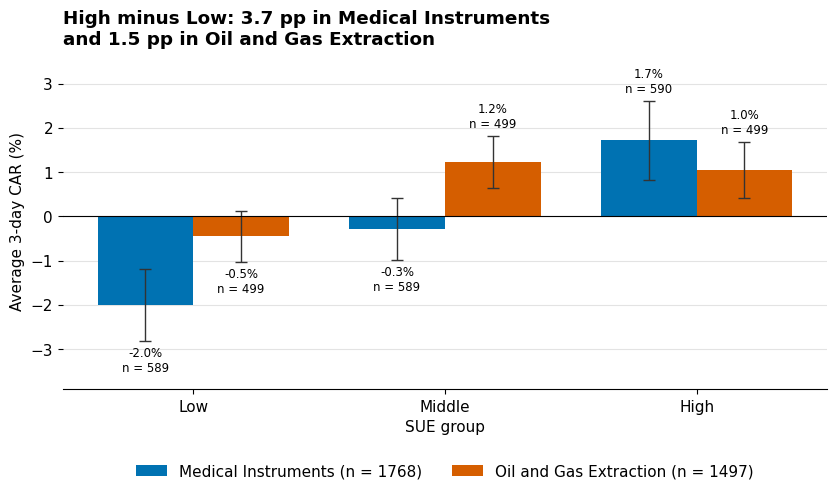

In [25]:
# ===== 5d. Figure 1: my industry vs the peer industry (class notebook; added the mean and n on each bar) =====
IND_COLORS = ["#0072B2", "#D55E00"]     # Okabe-Ito colorblind-safe: blue = Medical Instruments, vermillion = Oil and Gas Extraction (every figure)

def plot_compare(industries, colors, file_name):
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    x = np.arange(len(LABELS))
    width = 0.38
    for j, ind in enumerate(industries):
        t = ind.group_table()
        ax.bar(x + (j - 0.5) * width, t["mean"] * 100, width, yerr=t["ci95"] * 100, capsize=4,
               color=colors[j], label=f"{ind.name} (n = {len(ind.events)})",
               error_kw={"elinewidth": 1, "ecolor": "#333333"})
        for i, g in enumerate(LABELS):                                # mean and n on each bar
            m, c = t.loc[g, "mean"] * 100, t.loc[g, "ci95"] * 100
            ax.annotate(f"{m:.1f}%\nn = {t.loc[g, 'n']}", (x[i] + (j - 0.5) * width, m + c if m >= 0 else m - c),
                        xytext=(0, 4 if m >= 0 else -4), textcoords="offset points",
                        ha="center", va="bottom" if m >= 0 else "top", fontsize=8.5)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, LABELS)
    gaps = [ind.ttest()["High - Low (pp)"] for ind in industries]
    ax.set_title(f"High minus Low: {gaps[0]:.1f} pp in {industries[0].name}\n"
                 f"and {gaps[1]:.1f} pp in {industries[1].name}", loc="left", fontweight="bold")
    ax.set_xlabel("SUE group")
    ax.set_ylabel("Average 3-day CAR (%)")
    ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))   # legend under the chart
    ax.margins(y=0.2)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout()
    fig.savefig(file_name, dpi=200)
    plt.show()

plot_compare([mine, peer], colors=IND_COLORS, file_name="figures/figure1_car_by_sue_group.png")

**Figure 2. SUE and 3-day CAR, every announcement.** One dot per announcement, one color per industry (the same colors as Figure 1), and each industry's regression line CAR = a + b × SUE.
A steeper line means the stock reacts more to each unit of surprise; a wide cloud around the line means a small R². The x-axis shows the middle 98% of SUEs so the cloud is readable; the regressions use every announcement.

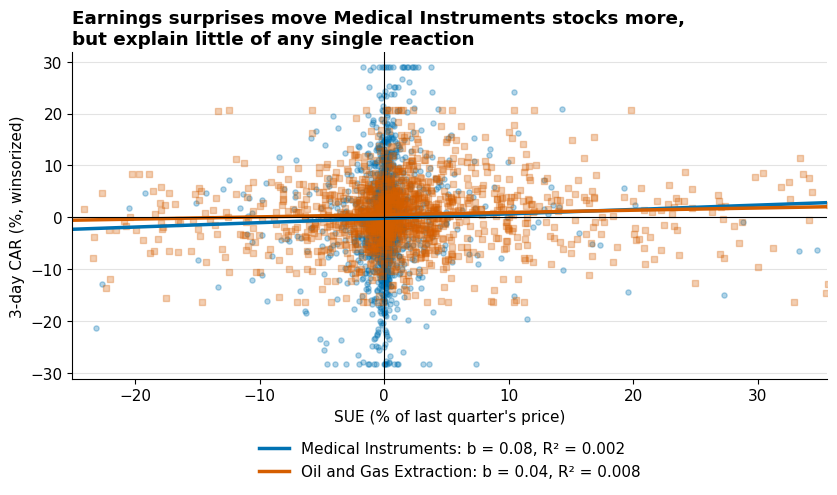

In [26]:
# ===== 5e. Figure 2: SUE vs CAR, both industries, each with its regression line (AI, see README; built from the 4c preview) =====
fig, ax = plt.subplots(figsize=(8.5, 5.2))
slopes = {}
for ind, color, marker in zip([mine, peer], IND_COLORS, ["o", "s"]):
    e = ind.events
    m = smf.ols("car_w ~ sue", data=e).fit()
    slopes[ind.name] = m.params["sue"]
    ax.scatter(e["sue"] * 100, e["car_w"] * 100, s=14, alpha=0.3, color=color, marker=marker)   # every announcement
    grid = pd.DataFrame({"sue": np.linspace(e["sue"].min(), e["sue"].max(), 200)})
    ax.plot(grid["sue"] * 100, m.predict(grid) * 100, color=color, linewidth=2.5,                # regression line
            label=f"{ind.name}: b = {m.params['sue']:.2f}, R² = {m.rsquared:.3f}")
all_sue = pd.concat([mine.events["sue"], peer.events["sue"]]) * 100
ax.set_xlim(all_sue.quantile(0.01), all_sue.quantile(0.99))                                    # middle 98% of SUEs
steeper = max(slopes, key=slopes.get)
if slopes[steeper] > 0:
    title = f"Earnings surprises move {steeper} stocks more,\nbut explain little of any single reaction"
else:
    title = "Higher SUE does not go with higher CAR in either industry"
ax.set_title(title, loc="left", fontweight="bold")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("SUE (% of last quarter's price)")
ax.set_ylabel("3-day CAR (%, winsorized)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig("figures/figure2_sue_vs_car.png", dpi=200)
plt.show()

**Figure 3. Why might the industries differ? One reason, checked with data.** Losses are less persistent than profits, so investors usually react less to a surprise from a loss-making company.
If Oil and Gas Extraction has more loss announcements, that could explain a weaker reaction there. The chart shows the share of announcements with a loss (EPS < 0);
the printout below it shows model (3): b is the slope for profitable announcements and `sue:loss` is how much the slope changes for loss announcements (negative = weaker reaction).
The reason can turn out to be wrong; what counts is that it is checked with data.

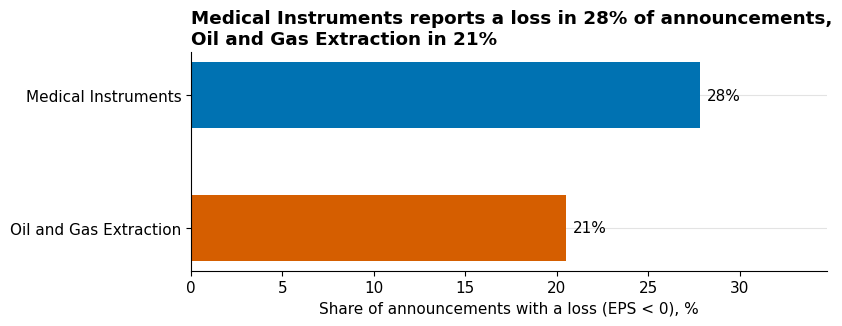

Medical Instruments: b (profitable) = 0.110 (p = 0.3343) | sue:loss = -0.104 (p = 0.4259)
Oil and Gas Extraction: b (profitable) = 0.033 (p = 0.0216) | sue:loss = 0.006 (p = 0.8049)


In [27]:
# ===== 5f. Figure 3: share of loss announcements, and does a loss weaken the reaction? (AI, see README) =====
share = pd.Series({ind.name: ind.events["loss"].mean() * 100 for ind in [mine, peer]})

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.barh(share.index, share.values, color=IND_COLORS, height=0.5)
for i, v in enumerate(share.values):
    ax.annotate(f"{v:.0f}%", (v, i), xytext=(5, 0), textcoords="offset points", va="center", fontsize=11)
ax.invert_yaxis()
ax.set_xlim(0, share.max() * 1.25)
ax.set_title(f"{share.idxmax()} reports a loss in {share.max():.0f}% of announcements,\n"
             f"{share.idxmin()} in {share.min():.0f}%", loc="left", fontweight="bold")
ax.set_xlabel("Share of announcements with a loss (EPS < 0), %")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig("figures/figure3_loss_share.png", dpi=200)
plt.show()

# Does a loss weaken the reaction? Model (3) for each industry.
for ind in [mine, peer]:
    m3 = ind.models()[2]
    print(f"{ind.name}: b (profitable) = {m3.params['sue']:.3f} (p = {m3.pvalues['sue']:.4f}) | "
          f"sue:loss = {m3.params['sue:loss']:.3f} (p = {m3.pvalues['sue:loss']:.4f})")

**Optional. Cumulative abnormal return from day −5 to +5.** For each SUE group, the average abnormal return on each trading day around the announcement, added up from day −5.
Flat lines before day 0 mean no early leak; the lines splitting on days 0 and +1 is the reaction the 3-day CAR measures; flat lines after mean the reaction is finished.
It uses the daily returns already pulled in `build()`, so there is no new WRDS query.

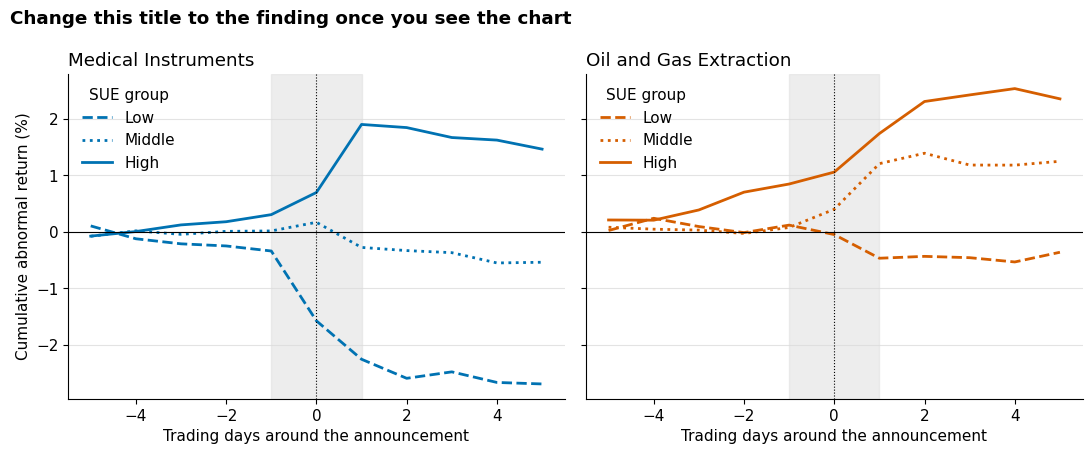

In [28]:
# ===== 5g. Optional: cumulative abnormal return from day -5 to +5 by SUE group (AI, see README) =====
STYLES = {"Low": "--", "Middle": ":", "High": "-"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)        # same y-axis for both industries
for ax, ind, color in zip(axes, [mine, peer], IND_COLORS):
    p = ind.events[["event_id", "permno", "n", "sue_group"]].merge(ind.stock[["permno", "tday", "ar"]], on="permno", how="inner")
    p["day"] = p["tday"] - p["n"]                                      # day relative to day 0
    p = p[(p["day"] >= -5) & (p["day"] <= 5)]
    cum = p.groupby(["sue_group", "day"], observed=True)["ar"].mean().unstack(0).cumsum() * 100
    for g in LABELS:
        ax.plot(cum.index, cum[g], linestyle=STYLES[g], color=color, linewidth=2, label=g)
    ax.axvspan(-1, 1, color="#DDDDDD", alpha=0.5)                      # the 3-day CAR window
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8, linestyle=":")
    ax.set_title(ind.name, loc="left")
    ax.set_xlabel("Trading days around the announcement")
    ax.legend(frameon=False, title="SUE group")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Cumulative abnormal return (%)")
fig.suptitle("Change this title to the finding once you see the chart",      # placeholder title
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
fig.savefig("figures/optional_car_day_minus5_to_plus5.png", dpi=200)
plt.show()

<div style="background:#eaf7ee; border-left:6px solid #2f855a; padding:8px 14px"><b>Why OOP helps here.</b> Adding a third industry is one line: <code>third = Industry("28", "Chemicals").build()</code>.
Every industry is built by the same code, so differences in the table come from the data, not from a copy that drifted.</div>

<div style="background:#e8f1fb; border-left:6px solid #2b6cb0; padding:8px 14px"><b>This project.</b> This notebook uses the class: <code>build()</code> runs the Project 2 steps (with <code>sue</code> and <code>car</code>), so Medical Instruments and Oil and Gas Extraction are built by exactly the same steps and rules.
Figures 1 to 3 and the optional chart are saved in the <code>figures</code> folder.</div>

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 6. Figures for slides</h2>

<div style="background:#e8f1fb; border-left:6px solid #2b6cb0; padding:8px 14px">The same four figures as Part 5, made presentation-ready for a non-technical audience: a 16:9-friendly size, larger text,
plain-language labels, the same industry names and colors everywhere, and titles that state the finding (built from the numbers where possible).
Part 5's figures are kept as they are; these versions are saved in the <code>figures</code> folder with names starting <code>slide_</code>.<br>
<b>Font and colors.</b> The slide figures use <b>IBM Plex Sans</b> and their own colors: steel blue <code>#3A6EA5</code> = Medical Instruments, rust <code>#C7622A</code> = Oil &amp; Gas Extraction (Part 5 keeps its colors).
For the font, put <code>IBMPlexSans-Regular.ttf</code> and <code>IBMPlexSans-Bold.ttf</code> in a folder called <code>fonts</code> next to this notebook (free from Google Fonts, SIL Open Font License).
If the files are not there, the figures use the default font and everything else still works.</div>

In [29]:
# ===== 6a. Slide style: sizes, fonts, names and colors used by every slide figure (AI, see README) =====
plt.rcParams.update({
    "font.size": 13, "axes.titlesize": 15, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 12, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#E3E3E3",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#BBBBBB", "axes.labelcolor": "#555555",                      # lighter axes
    "xtick.color": "#BBBBBB", "ytick.color": "#BBBBBB",
    "xtick.labelcolor": "#555555", "ytick.labelcolor": "#555555"})

# IBM Plex Sans from the fonts folder; the default font is used if the files are not there
import glob
from matplotlib import font_manager
plex_files = glob.glob("fonts/IBMPlexSans-*.ttf")
for f in plex_files:
    font_manager.fontManager.addfont(f)
if plex_files:
    plt.rcParams["font.family"] = "IBM Plex Sans"
    print("Slide font: IBM Plex Sans")
else:
    print("IBM Plex Sans not found in the fonts folder: the slide figures use the default font")

SLIDE_COLORS = ["#3A6EA5", "#C7622A"]          # steel blue = Medical Instruments, rust = Oil & Gas Extraction (Part 6 only)
SLIDE_SIZE = (10, 5.6)                                                    # 16:9-friendly
INDS  = [mine, peer]
NAMES = ["Medical Instruments (SIC 38)", "Oil & Gas Extraction (SIC 13)"]            # the same labels on every slide
CAR_LABEL = "Average 3-day return vs. market (%)"
SUE_LABEL = "Earnings surprise (EPS change, % of share price)"

def slide_title(fig, title, subtitle=None):
    """One-line finding as the title, detail in a smaller grey subtitle, both at the top left of the figure."""
    fig.text(0.01, 0.98, title, ha="left", va="top", fontsize=17, fontweight="bold", color="#222222")
    if subtitle:
        fig.text(0.01, 0.915, subtitle, ha="left", va="top", fontsize=12.5, color="#666666")

def p_text(p):
    """p-value in plain form for a slide."""
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

Slide font: IBM Plex Sans


**Figure 1. Average 3-day return by surprise group.** Changes from Part 5: a title that states the takeaway, the t-test (High minus Low) shown as a bracket for each industry,
x-axis labels that explain the groups and carry the number of announcements, one value per bar, and a plain-language y-axis.
Note for the talk: in Oil & Gas the Middle group is slightly above the High group; their intervals overlap, so that gap is likely noise.

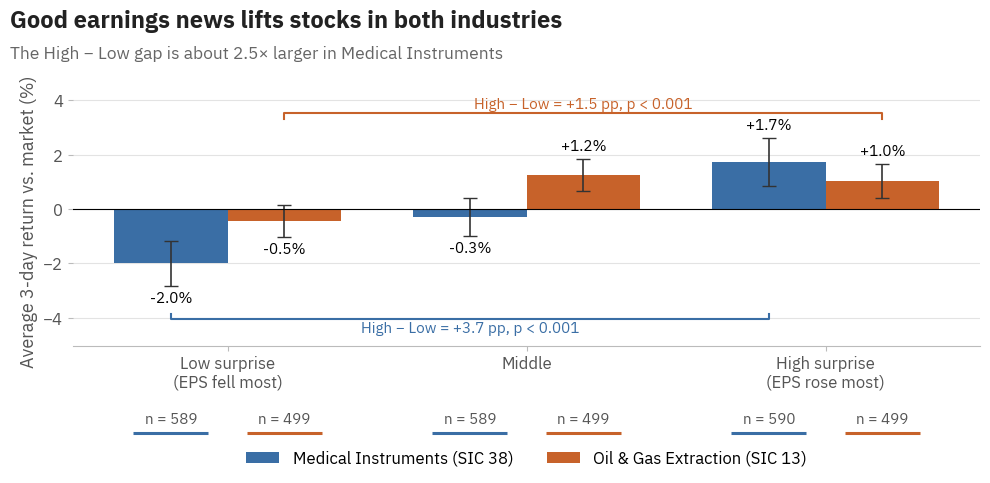

In [30]:
# ===== 6b. Slide Figure 1: average 3-day return by SUE group, with the t-test on the chart (AI, see README) =====
tabs = [ind.group_table() for ind in INDS]
tts  = [ind.ttest() for ind in INDS]

fig, ax = plt.subplots(figsize=SLIDE_SIZE)
x = np.arange(len(LABELS))
width = 0.38
for j, (t, color, name) in enumerate(zip(tabs, SLIDE_COLORS, NAMES)):
    xs = x + (j - 0.5) * width
    ax.bar(xs, t["mean"] * 100, width, yerr=t["ci95"] * 100, capsize=5, color=color, label=name,
           error_kw={"elinewidth": 1.2, "ecolor": "#333333"})
    for i, g in enumerate(LABELS):                                        # one value per bar
        m, c = t.loc[g, "mean"] * 100, t.loc[g, "ci95"] * 100
        ax.annotate(f"{m:+.1f}%", (xs[i], m + c if m >= 0 else m - c), xytext=(0, 4 if m >= 0 else -4),
                    textcoords="offset points", ha="center", va="bottom" if m >= 0 else "top", fontsize=11)

# the t-test as a bracket from Low to High: SIC 38 (blue) below the bars, SIC 13 (orange) above
top     = max(((t["mean"] + t["ci95"]) * 100).max() for t in tabs)
low_end = min(((t["mean"] - t["ci95"]) * 100).min() for t in tabs)
span = top - min(low_end, 0)
d = 0.06 * span                                                           # bracket and gap size, scaled to the chart
for j, (tt, color) in enumerate(zip(tts, SLIDE_COLORS)):
    x0, x1 = x[0] + (j - 0.5) * width, x[2] + (j - 0.5) * width
    label = f"High − Low = {tt['High - Low (pp)']:+.1f} pp, {p_text(tt['p (t-test)'])}"
    if j == 0:                                                            # below: bracket opens upward, label under it
        y = min(low_end, 0) - 3.8 * d
        ax.plot([x0, x0, x1, x1], [y + d * 0.6, y, y, y + d * 0.6], color=color, linewidth=1.5)
        ax.text((x0 + x1) / 2, y - d * 0.25, label, ha="center", va="top", color=color, fontsize=11)
    else:                                                                 # above: bracket opens downward, label over it
        y = top + 2.8 * d
        ax.plot([x0, x0, x1, x1], [y - d * 0.6, y, y, y - d * 0.6], color=color, linewidth=1.5)
        ax.text((x0 + x1) / 2, y + d * 0.25, label, ha="center", va="bottom", color=color, fontsize=11)
ax.set_ylim(bottom=min(low_end, 0) - 6.8 * d, top=top + 4.6 * d)

# x-axis: group names, then each industry's n under its own bar, underlined in the industry color
ax.set_xticks(x, ["Low surprise\n(EPS fell most)", "Middle\n ", "High surprise\n(EPS rose most)"])
from matplotlib.transforms import blended_transform_factory, offset_copy
base = blended_transform_factory(ax.transData, ax.transAxes)
text_tf = offset_copy(base, fig=fig, y=-48, units="points")
line_tf = offset_copy(base, fig=fig, y=-63, units="points")
for j, (t, color) in enumerate(zip(tabs, SLIDE_COLORS)):
    for i, g in enumerate(LABELS):
        xc = x[i] + (j - 0.5) * width
        ax.text(xc, 0, f"n = {t.loc[g, 'n']:,}", transform=text_tf, ha="center", va="top", fontsize=11, color="#555555")
        ax.plot([xc - width * 0.33, xc + width * 0.33], [0, 0], transform=line_tf, color=color, linewidth=2.2,
                solid_capstyle="butt", clip_on=False)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel(CAR_LABEL)

gaps = [tt["High - Low (pp)"] for tt in tts]
if all(g > 0 for g in gaps) and all(tt["p (t-test)"] < 0.05 for tt in tts):
    big = int(np.argmax(gaps))
    title = "Good earnings news lifts stocks in both industries"
    subtitle = f"The High − Low gap is about {max(gaps) / min(gaps):.1f}× larger in {NAMES[big].split(' (')[0]}"
else:
    title, subtitle = "How stocks react to earnings surprises", None
slide_title(fig, title, subtitle)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.36))
ax.spines["left"].set_visible(False)
plt.tight_layout(rect=(0, 0, 1, 0.86))
fig.savefig("figures/slide_figure1_car_by_sue_group.png", dpi=200)
plt.show()

**Figure 2. Earnings surprise and 3-day return, every announcement.** Changes from Part 5: the title is chosen from the **clustered** p-values (Part 4 and the six-column table),
so it never claims a link that is not significant; the legend says which slopes are significant; each line has its 95% confidence band (wide = imprecise);
large dots show the average return in 20 equal-sized surprise buckets, so the trend is easy to see; the axes show the middle 90% of announcements, while the lines, bands and buckets use every announcement.

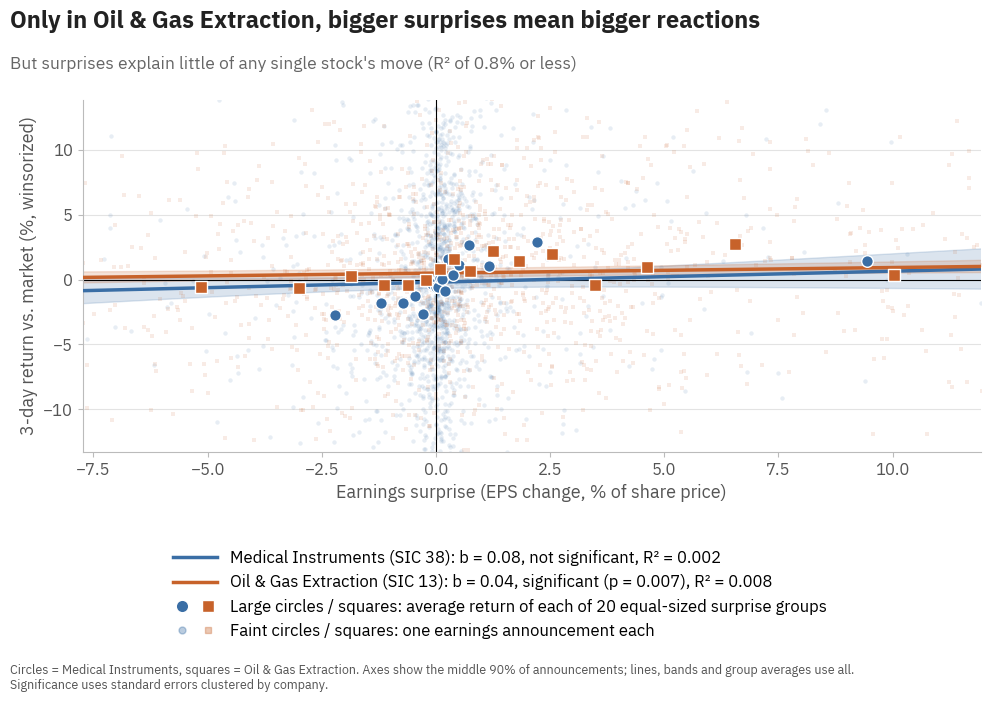

In [31]:
# ===== 6c. Slide Figure 2: scatter, regression lines with 95% bands, and bucket averages (AI, see README) =====
fig, ax = plt.subplots(figsize=(10, 7))                                  # taller, to fit the four-line legend
info = []
for ind, color, name, marker in zip(INDS, SLIDE_COLORS, NAMES, ["o", "s"]):
    e = ind.events
    m = ind.models()[0]                                                   # model (1), clustered standard errors
    b, p, r2 = m.params["sue"], m.pvalues["sue"], m.rsquared
    info.append((name, b, p, r2))
    ax.scatter(e["sue"] * 100, e["car_w"] * 100, s=10, alpha=0.12, color=color, marker=marker, linewidths=0)   # faint dots
    bins = e.assign(bucket=pd.qcut(e["sue"].rank(method="first"), 20, labels=False)) \
            .groupby("bucket")[["sue", "car_w"]].mean()                    # 20 equal-sized buckets
    ax.scatter(bins["sue"] * 100, bins["car_w"] * 100, s=70, color=color, marker=marker,
               edgecolor="white", linewidth=1, zorder=4)
    grid = pd.DataFrame({"sue": np.linspace(e["sue"].min(), e["sue"].max(), 200)})
    pred = m.get_prediction(grid).summary_frame(alpha=0.05)
    ax.fill_between(grid["sue"] * 100, pred["mean_ci_lower"] * 100, pred["mean_ci_upper"] * 100, color=color, alpha=0.18)
    sig = f"significant ({p_text(p)})" if p < 0.05 else "not significant"
    ax.plot(grid["sue"] * 100, pred["mean"] * 100, color=color, linewidth=2.5, zorder=3,
            label=f"{name}: b = {b:.2f}, {sig}, R² = {r2:.3f}")

all_sue = pd.concat([ind.events["sue"] for ind in INDS]) * 100
all_car = pd.concat([ind.events["car_w"] for ind in INDS]) * 100
ax.set_xlim(all_sue.quantile(0.05), all_sue.quantile(0.95))            # middle 90% of announcements
ax.set_ylim(all_car.quantile(0.05), all_car.quantile(0.95))
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)

sig_names = [n.split(" (")[0] for n, b, p, r2 in info if p < 0.05 and b > 0]
if len(sig_names) == 1:
    title = f"Only in {sig_names[0]}, bigger surprises mean bigger reactions"
elif len(sig_names) == 2:
    title = "In both industries, bigger surprises mean bigger reactions"
else:
    title = "Surprise size doesn't reliably predict the reaction"
max_r2 = max(r2 for n, b, p, r2 in info)
lead = "But surprises" if sig_names else "Surprises also"
slide_title(fig, title, f"{lead} explain little of any single stock's move (R² of {max_r2:.1%} or less)")
ax.set_xlabel(SUE_LABEL)
ax.set_ylabel("3-day return vs. market (%, winsorized)")
# legend: the two regression lines, plus what the large and the faint markers are
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
line_handles, line_labels = ax.get_legend_handles_labels()
big = tuple(Line2D([], [], linestyle="none", marker=mk, markersize=9, color=c, markeredgecolor="white")
            for c, mk in zip(SLIDE_COLORS, ["o", "s"]))
small = tuple(Line2D([], [], linestyle="none", marker=mk, markersize=5, color=c, alpha=0.35)
              for c, mk in zip(SLIDE_COLORS, ["o", "s"]))
fig.legend(line_handles + [big, small],
          line_labels + ["Large circles / squares: average return of each of 20 equal-sized surprise groups",
                         "Faint circles / squares: one earnings announcement each"],
          handler_map={tuple: HandlerTuple(ndivide=None, pad=0.6)}, handlelength=2.6,
          frameon=False, loc="lower center", bbox_to_anchor=(0.5, 0.06))
fig.text(0.01, 0.01, "Circles = Medical Instruments, squares = Oil & Gas Extraction. Axes show the middle 90% of announcements; "
         "lines, bands and group averages use all.\nSignificance uses standard errors clustered by company.",
         fontsize=9, color="#555555")
plt.tight_layout(rect=(0, 0.25, 1, 0.88))
fig.savefig("figures/slide_figure2_sue_vs_car.png", dpi=200)
plt.show()

**Figure 3a. Losses: how common are they?** Changes from Part 5: the share of loss announcements with the counts behind each percentage, and a title that states which industry reports losses more often.

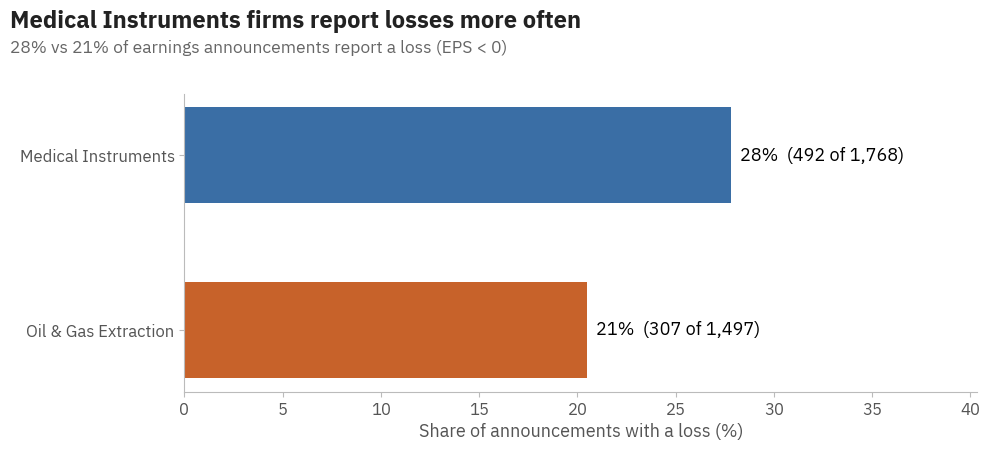

In [32]:
# ===== 6d. Slide Figure 3a: share of loss announcements (AI, see README) =====
shares = [ind.events["loss"].mean() * 100 for ind in INDS]
counts = [(int(ind.events["loss"].sum()), len(ind.events)) for ind in INDS]
short  = [n.split(" (")[0] for n in NAMES]

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(short, shares, color=SLIDE_COLORS, height=0.55)
for i, (v, (k, n)) in enumerate(zip(shares, counts)):
    ax.annotate(f"{v:.0f}%  ({k:,} of {n:,})", (v, i), xytext=(6, 0), textcoords="offset points", va="center", fontsize=13)
ax.invert_yaxis()
ax.set_xlim(0, max(shares) * 1.45)
ax.set_xlabel("Share of announcements with a loss (%)")
ax.grid(False)

big = int(np.argmax(shares))
slide_title(fig, f"{short[big]} firms report losses more often",
            f"{shares[big]:.0f}% vs {shares[1 - big]:.0f}% of earnings announcements report a loss (EPS < 0)")
plt.tight_layout(rect=(0, 0, 1, 0.84))
fig.savefig("figures/slide_figure3a_loss_share.png", dpi=200)
plt.show()

**Figure 3b. Do losses matter?** The average 3-day return for profitable (solid) and loss (hatched) announcements in each industry, with 95% confidence intervals and a legend for the four bars.
The footnote gives the model (3) loss effect, which holds the surprise and the year fixed.

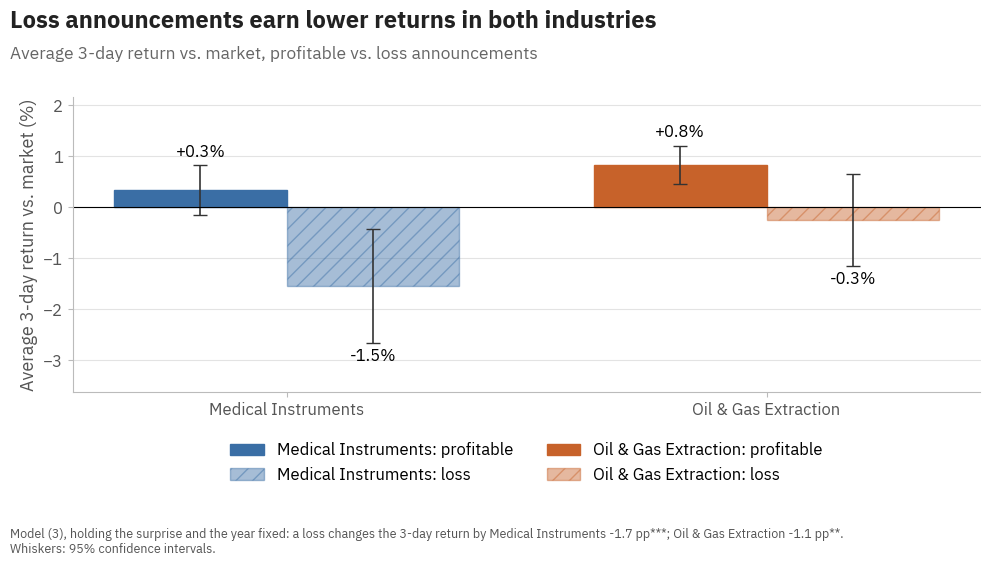

In [33]:
# ===== 6d2. Slide Figure 3b: average 3-day return of profitable vs loss announcements (AI, see README) =====
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=SLIDE_SIZE)
x = np.arange(len(INDS))
width = 0.36
STYLE = [("Profitable", 0, "", 1.0), ("Loss", 1, "//", 0.45)]          # (label, loss flag, hatch, alpha)
means = {}
for k, (lab, flag, hatch, alpha) in enumerate(STYLE):
    vals, cis = [], []
    for ind in INDS:
        c = ind.events.loc[ind.events["loss"] == flag, "car"]
        vals.append(c.mean() * 100)
        cis.append(1.96 * c.std() / np.sqrt(len(c)) * 100)
    means[lab] = vals
    xs = x + (k - 0.5) * width
    ax.bar(xs, vals, width, yerr=cis, capsize=5, color=SLIDE_COLORS, alpha=alpha, hatch=hatch,
           edgecolor=SLIDE_COLORS, error_kw={"elinewidth": 1.2, "ecolor": "#333333"})
    for xi, v, c in zip(xs, vals, cis):
        ax.annotate(f"{v:+.1f}%", (xi, v + c if v >= 0 else v - c), xytext=(0, 4 if v >= 0 else -4),
                    textcoords="offset points", ha="center", va="bottom" if v >= 0 else "top", fontsize=12)
ax.set_xticks(x, short)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel(CAR_LABEL)
ax.margins(y=0.25)

# legend: solid = profitable, hatched = loss, in each industry's color
handles = []
for name, color in zip(short, SLIDE_COLORS):
    for lab, flag, hatch, alpha in STYLE:
        handles.append(Patch(facecolor=color, edgecolor=color, alpha=alpha, hatch=hatch, label=f"{name}: {lab.lower()}"))
ax.legend(handles=handles, ncol=2, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))

loss_lower = all(l < p for l, p in zip(means["Loss"], means["Profitable"]))
slide_title(fig, "Loss announcements earn lower returns in both industries" if loss_lower
            else "How loss announcements compare with profitable ones",
            "Average 3-day return vs. market, profitable vs. loss announcements")
m3s = [ind.models()[2] for ind in INDS]
stars = lambda p: "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else " (n.s.)"
fig.text(0.01, 0.01, "Model (3), holding the surprise and the year fixed: a loss changes the 3-day return by "
         + "; ".join(f"{s} {m.params['loss'] * 100:+.1f} pp{stars(m.pvalues['loss'])}" for s, m in zip(short, m3s))
         + ".\nWhiskers: 95% confidence intervals.", fontsize=9, color="#555555")
plt.tight_layout(rect=(0, 0.06, 1, 0.86))
fig.savefig("figures/slide_figure3b_loss_vs_profit.png", dpi=200)
plt.show()

**Figure 4. When does the price move?** Changes from Part 5: a title that states the finding (written from the WRDS results; check it still fits if the data changes),
the shaded area labeled as the 3-day window used for CAR, and one shared legend for the line styles.
Note for the talk: the Oil & Gas Middle group rises by about 1%, the same pattern as its Middle bar in Figure 1.

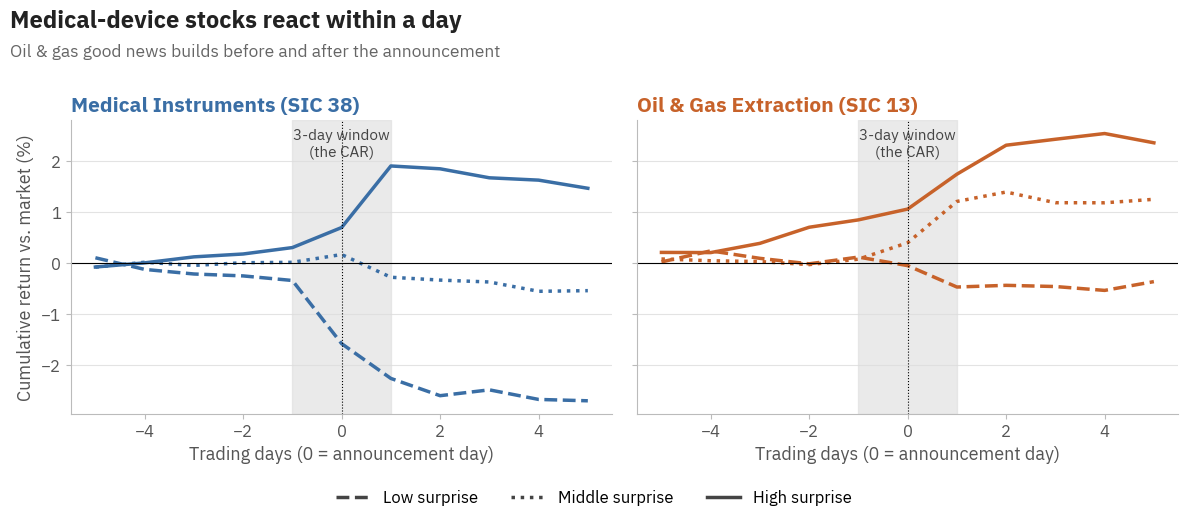

In [34]:
# ===== 6e. Slide optional figure: cumulative abnormal return from day -5 to +5 by SUE group (AI, see README) =====
from matplotlib.lines import Line2D
STYLES = {"Low": "--", "Middle": ":", "High": "-"}

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)       # same y-axis for both industries
for ax, ind, color, name in zip(axes, INDS, SLIDE_COLORS, NAMES):
    p = ind.events[["event_id", "permno", "n", "sue_group"]].merge(ind.stock[["permno", "tday", "ar"]], on="permno", how="inner")
    p["day"] = p["tday"] - p["n"]
    p = p[(p["day"] >= -5) & (p["day"] <= 5)]
    cum = p.groupby(["sue_group", "day"], observed=True)["ar"].mean().unstack(0).cumsum() * 100
    for g in LABELS:
        ax.plot(cum.index, cum[g], linestyle=STYLES[g], color=color, linewidth=2.5)
    ax.axvspan(-1, 1, color="#DDDDDD", alpha=0.6)
    ax.text(0, 0.97, "3-day window\n(the CAR)", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=11, color="#444444")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8, linestyle=":")
    ax.set_title(name, loc="left", color=color, fontweight="bold")
    ax.set_xlabel("Trading days (0 = announcement day)")
axes[0].set_ylabel("Cumulative return vs. market (%)")

handles = [Line2D([0], [0], color="#444444", linestyle=STYLES[g], linewidth=2.5, label=f"{g} surprise") for g in LABELS]
fig.legend(handles=handles, frameon=False, ncol=3, loc="lower center")
slide_title(fig, "Medical-device stocks react within a day",                     # written from the WRDS results
            "Oil & gas good news builds before and after the announcement")
plt.tight_layout(rect=(0, 0.07, 1, 0.85))
fig.savefig("figures/slide_optional_car_day_minus5_to_plus5.png", dpi=200)
plt.show()

<h2 style="background:#7b1e1e; color:white; padding:8px 14px; border-radius:4px">Part 7. Project 3 checklist</h2>

**Analysis**

- [ ] Your Project 2 table, revised with my comments (rules 1 to 6, the sample construction table).
- [ ] Outliers: say what you did (the rules, and winsorizing CAR at 1%/99% or not) and show that the result does not depend on it.
- [ ] **Figure 1**: average CAR by SUE group with 95% CI.
- [ ] **t-test** High vs Low, in two plain sentences.
- [ ] **Regression** CAR = a + b × SUE: b in plain words (for SUE + 0.01), its p-value, R², and n.
- [ ] **Peer industry**: the same steps, one comparison table, and Figure 3.

**Figures (every figure)**

- [ ] The title states the **finding**, not the topic.
- [ ] Axis labels with **units** (%).
- [ ] The **same color for the same thing** on every slide.
- [ ] A line at 0.

**Interpretation**

- Results do **not** need to be significant. Explain what you find and what it means for the client.
- Name at least one **limitation** (small R², few companies, one period, CAR measures only 3 days).

**Before you submit:** Kernel > Restart & Run All, and check that every number in the report matches the notebook.

In [35]:
conn.close()